In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('C:/Users/Marun Yory/Desktop/Synthetic_Transportation_Prediction/documents/Synthetic_Transportation_Dataset_Expanded_v2.csv')

In [4]:
df.head()

,Record_ID,Timestamp,Latitude,Longitude,Road_ID,Vehicle_Count,Avg_Speed(km/h),Vehicle_Type,Traffic_Density,Weather,Visibility(m),Road_Condition,Accident_Occurred,Accident_Severity,Alert_Generated,temperature,humidity
0,1,03-10-2023 09:50,32.004714,76.971961,RD-285,419,90,Mixed,Medium,Fog,5663,Under Maintenance,Yes,Major,Yes,31.24,61.12
1,2,09-06-2019 08:01,10.632732,77.828652,RD-384,232,104,Mixed,Very High,Rain,896,Wet,No,-,No,48.52,33.07
2,3,08-01-2020 01:38,12.258165,88.810189,RD-282,339,100,Bus,Medium,Storm,9369,Under Maintenance,No,-,No,41.96,43.97
3,4,18-10-2022 05:43,34.289950,95.415253,RD-128,74,63,Car,Low,Clear,2510,Slippery,Yes,Fatal,No,37.96,59.52
4,5,29-06-2023 23:11,31.698993,77.675486,RD-49,187,73,Mixed,Low,Storm,3447,Wet,No,-,No,24.68,48.61


In [5]:
df.shape

(5500, 17)

In [6]:
df.isnull().sum()

Record_ID            0
Timestamp            0
Latitude             0
Longitude            0
Road_ID              0
Vehicle_Count        0
Avg_Speed(km/h)      0
Vehicle_Type         0
Traffic_Density      0
Weather              0
Visibility(m)        0
Road_Condition       0
Accident_Occurred    0
Accident_Severity    0
Alert_Generated      0
temperature          0
humidity             0
dtype: int64

In [7]:
df[df.isnull().any(axis=1)]

,Record_ID,Timestamp,Latitude,Longitude,Road_ID,Vehicle_Count,Avg_Speed(km/h),Vehicle_Type,Traffic_Density,Weather,Visibility(m),Road_Condition,Accident_Occurred,Accident_Severity,Alert_Generated,temperature,humidity


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Record_ID          5500 non-null   int64  
 1   Timestamp          5500 non-null   str    
 2   Latitude           5500 non-null   float64
 3   Longitude          5500 non-null   float64
 4   Road_ID            5500 non-null   str    
 5   Vehicle_Count      5500 non-null   int64  
 6   Avg_Speed(km/h)    5500 non-null   int64  
 7   Vehicle_Type       5500 non-null   str    
 8   Traffic_Density    5500 non-null   str    
 9   Weather            5500 non-null   str    
 10  Visibility(m)      5500 non-null   int64  
 11  Road_Condition     5500 non-null   str    
 12  Accident_Occurred  5500 non-null   str    
 13  Accident_Severity  5500 non-null   str    
 14  Alert_Generated    5500 non-null   str    
 15  temperature        5500 non-null   float64
 16  humidity           5500 non-null   

In [9]:
df.nunique()

Record_ID            5500
Timestamp            5495
Latitude             5500
Longitude            5500
Road_ID               500
Vehicle_Count         490
Avg_Speed(km/h)       115
Vehicle_Type            5
Traffic_Density         4
Weather                 5
Visibility(m)        4173
Road_Condition          4
Accident_Occurred       2
Accident_Severity       4
Alert_Generated         2
temperature          2502
humidity             3638
dtype: int64

In [10]:
df.describe()

,Record_ID,Latitude,Longitude,Vehicle_Count,Avg_Speed(km/h),Visibility(m),temperature,humidity
count,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,2750.500000,22.572905,82.476797,254.092364,61.324909,5046.928364,34.903933,59.617035
std,1587.857571,8.356760,8.356606,141.397428,33.207133,2806.171704,8.674031,17.155972
min,1.000000,8.000245,68.007834,10.000000,5.000000,201.000000,20.000000,30.000000
25%,1375.750000,15.480326,75.370574,131.000000,33.000000,2640.000000,27.400000,44.800000
50%,2750.500000,22.616598,82.322999,255.000000,60.000000,5007.000000,34.935000,59.510000
75%,4125.250000,29.930907,89.738211,377.250000,90.000000,7515.000000,42.382500,74.292500
max,5500.000000,36.998251,96.991006,499.000000,119.000000,9998.000000,49.990000,89.980000


In [11]:
df.drop(columns=['Timestamp', 'Road_ID'], inplace=True)

In [12]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns
print(categorical_cols)

Index(['Vehicle_Type', 'Traffic_Density', 'Weather', 'Road_Condition',
       'Accident_Occurred', 'Accident_Severity', 'Alert_Generated'],
      dtype='str')


In [13]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
numeric_cols

Index(['Record_ID', 'Latitude', 'Longitude', 'Vehicle_Count',
       'Avg_Speed(km/h)', 'Visibility(m)', 'temperature', 'humidity'],
      dtype='str')

In [14]:
df['Vehicle_Type'].value_counts()

Vehicle_Type
Car      1172
Bus      1103
Mixed    1096
Bike     1071
Truck    1058
Name: count, dtype: int64

In [15]:
df['Traffic_Density'].value_counts()

Traffic_Density
Low          1422
Medium       1390
Very High    1358
High         1330
Name: count, dtype: int64

In [17]:
df['Road_Condition'].value_counts()

Road_Condition
Dry                  1391
Slippery             1389
Under Maintenance    1379
Wet                  1341
Name: count, dtype: int64

In [18]:
df['Accident_Occurred'].value_counts()

Accident_Occurred
No     4925
Yes     575
Name: count, dtype: int64

In [19]:
df['Accident_Severity'].value_counts()

Accident_Severity
-        5056
Minor     156
Fatal     147
Major     141
Name: count, dtype: int64

In [20]:
df['Alert_Generated'].value_counts()

Alert_Generated
No     4397
Yes    1103
Name: count, dtype: int64

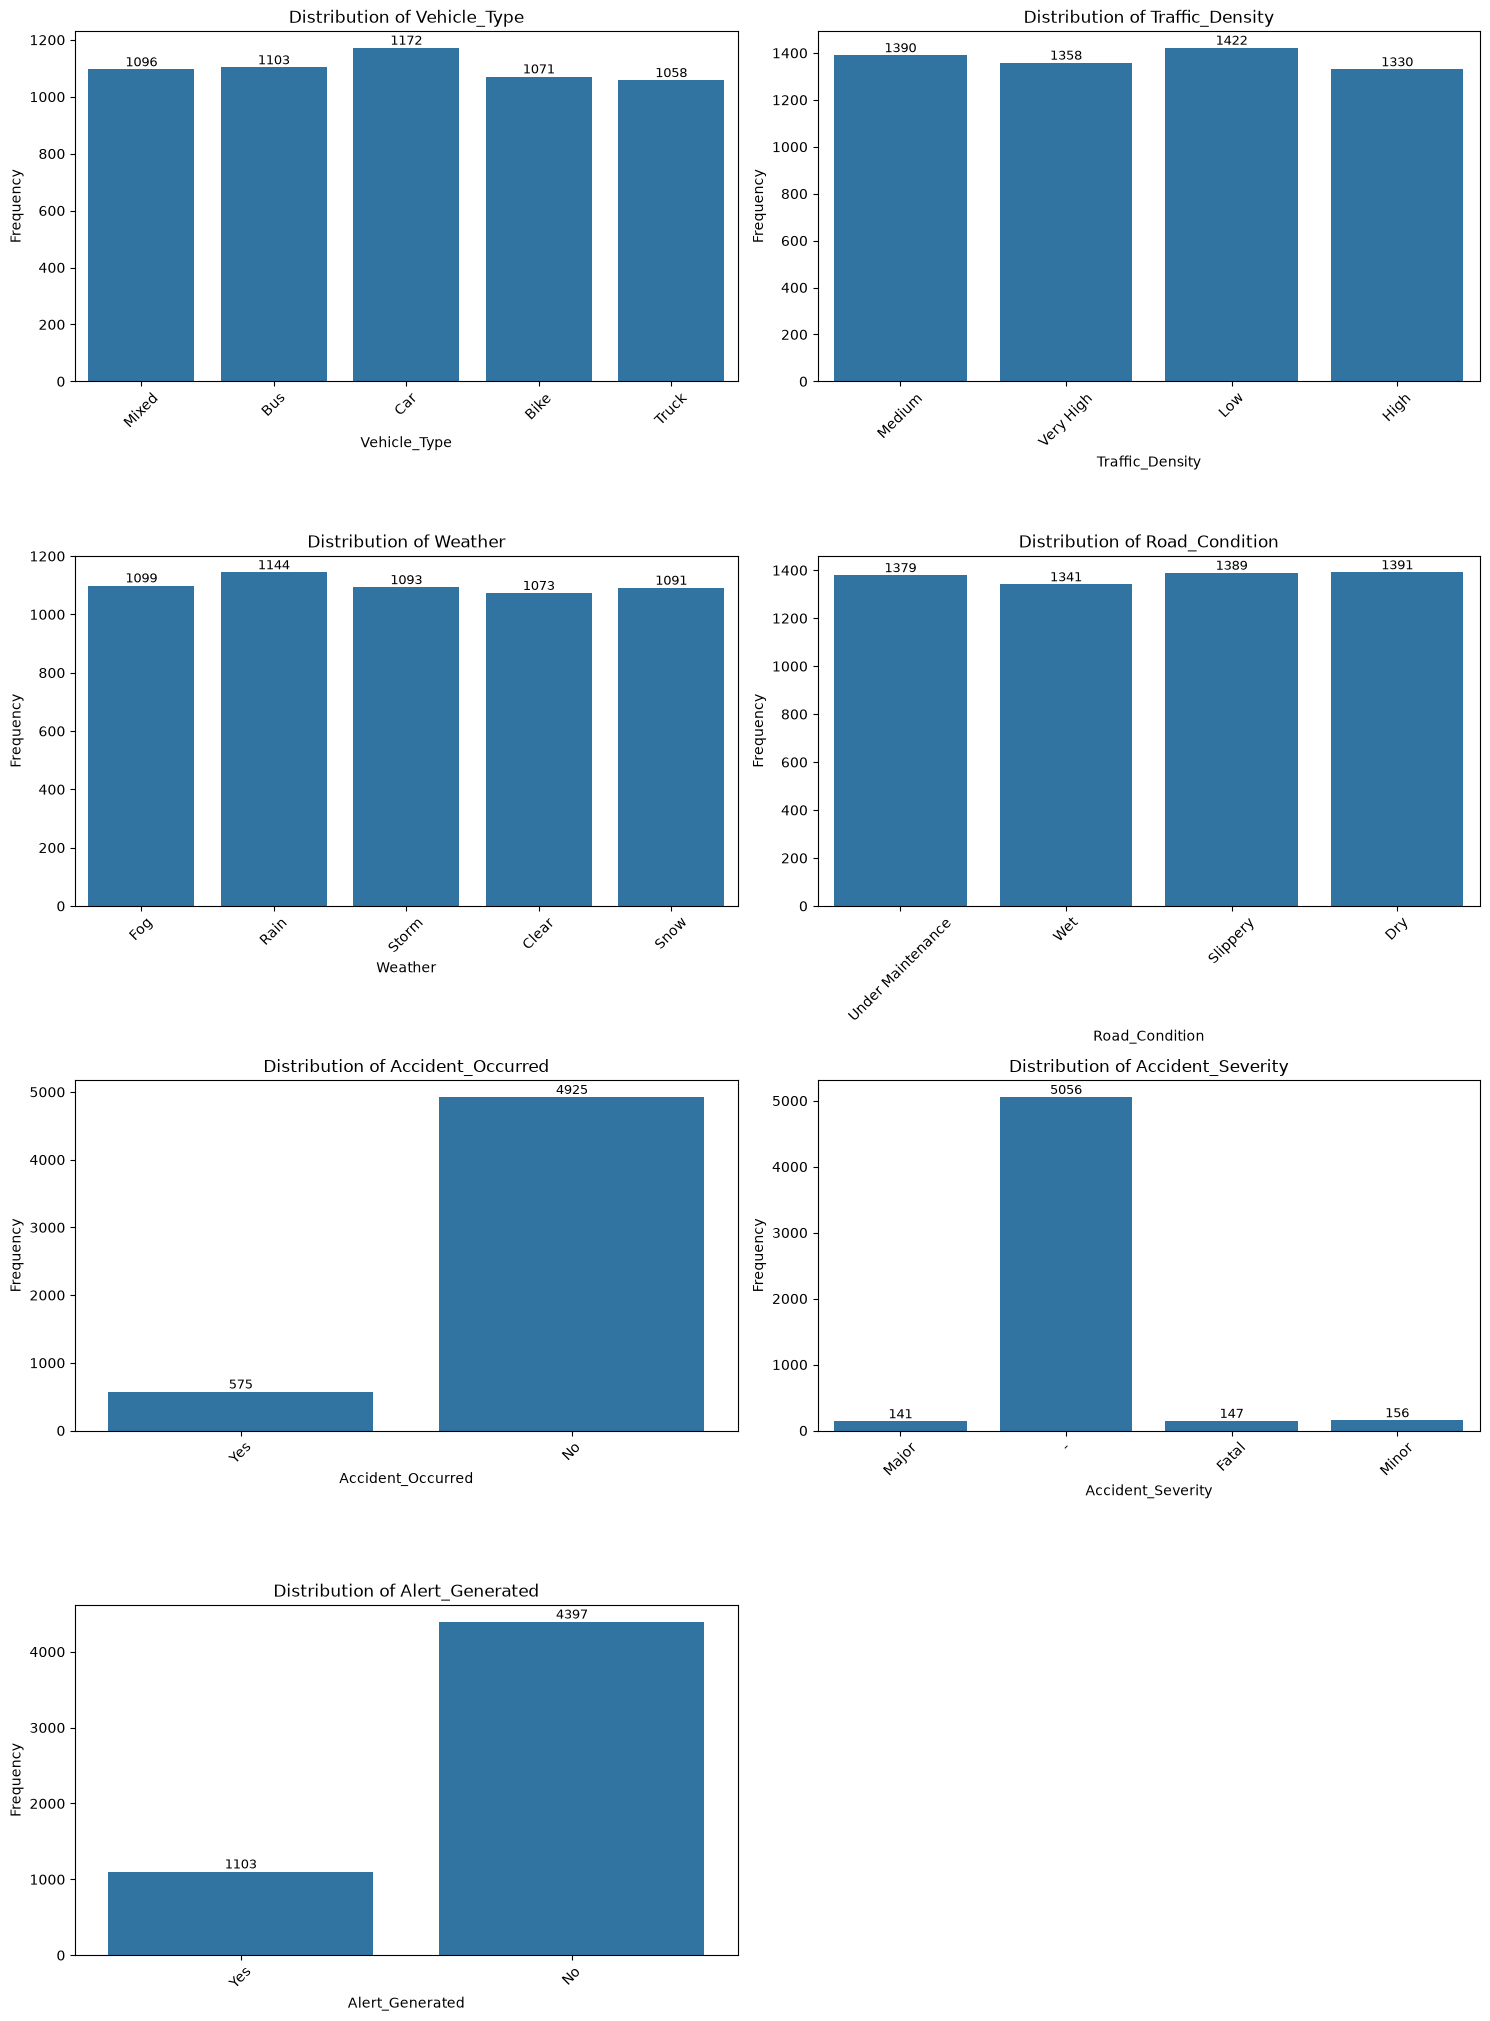

In [21]:
plt.figure(figsize=(15, 25))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(5, 2, i)

    ax = sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Add count labels
    for p in ax.patches:
        height = p.get_height()
        ax.text(p.get_x() + p.get_width()/2, 
                height + 0.5, 
                int(height),
                ha='center', va='bottom', fontsize=9)

    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

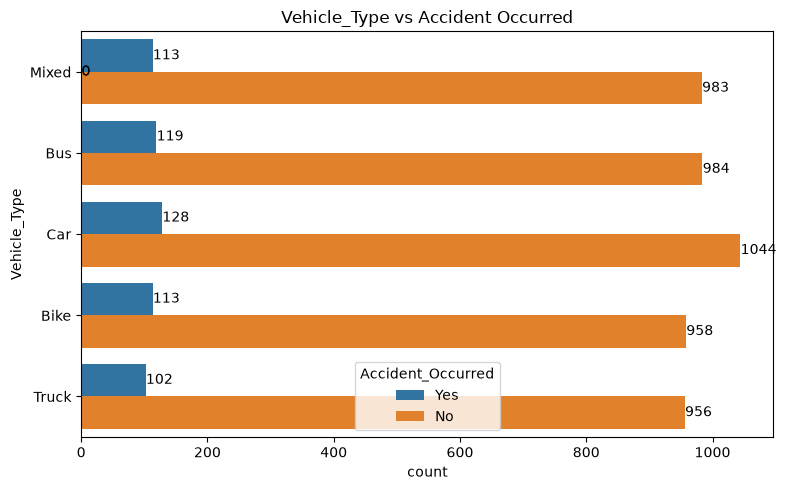

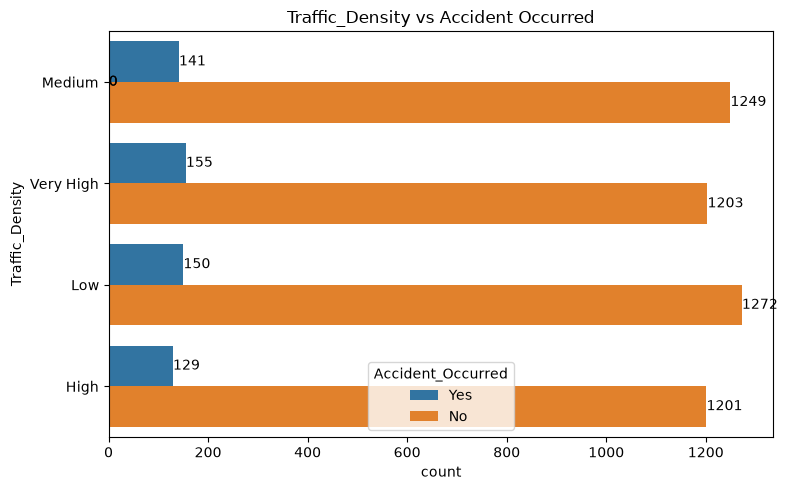

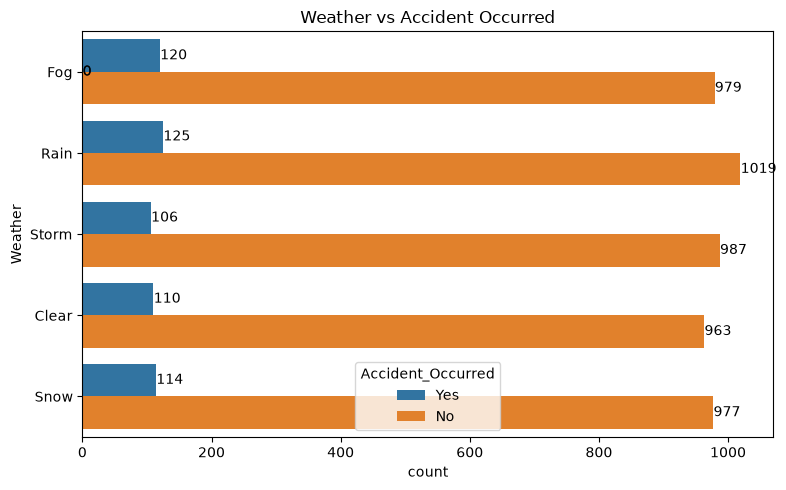

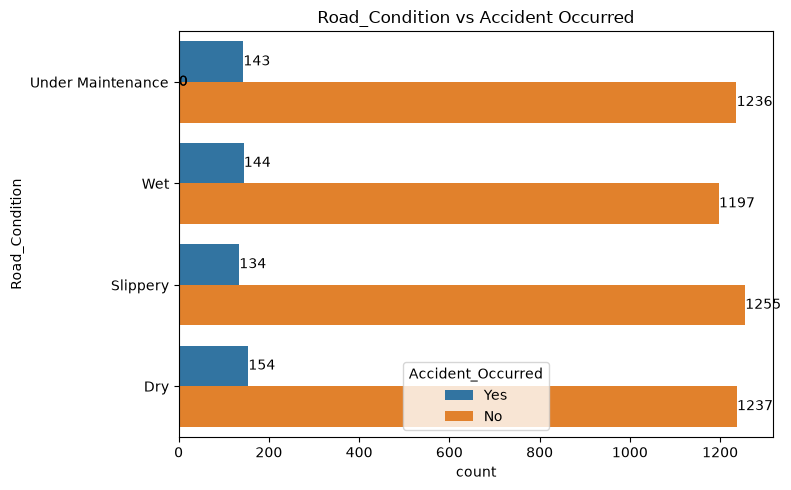

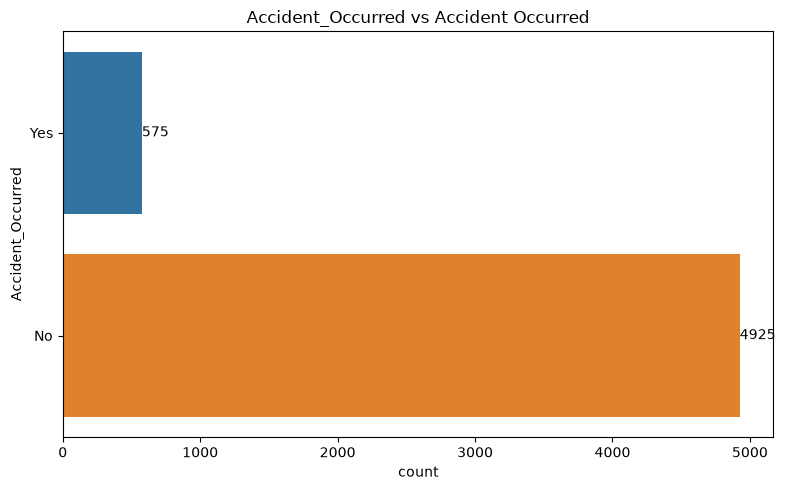

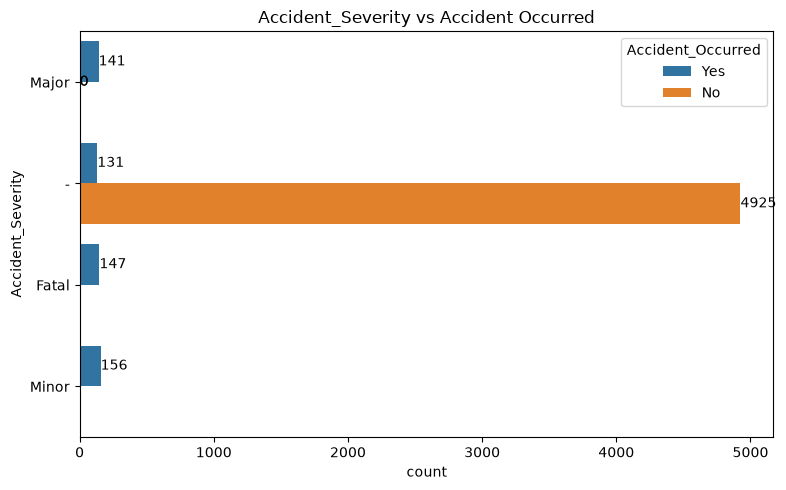

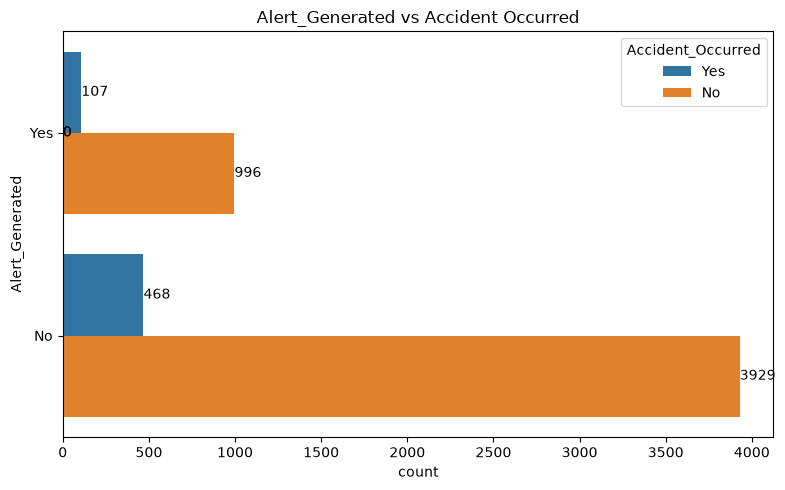

In [22]:
for col in categorical_cols:
    plt.figure(figsize=(8, 5))
    ax = sns.countplot(y=col, hue='Accident_Occurred', data=df)
    plt.title(f'{col} vs Accident Occurred')

    # Add count labels on each bar
    for p in ax.patches:
        count = int(p.get_width())   # bar length = count
        y = p.get_y() + p.get_height() / 2
        ax.text(p.get_width() + 0.5, y, count, va='center')

    plt.tight_layout()
    plt.show()

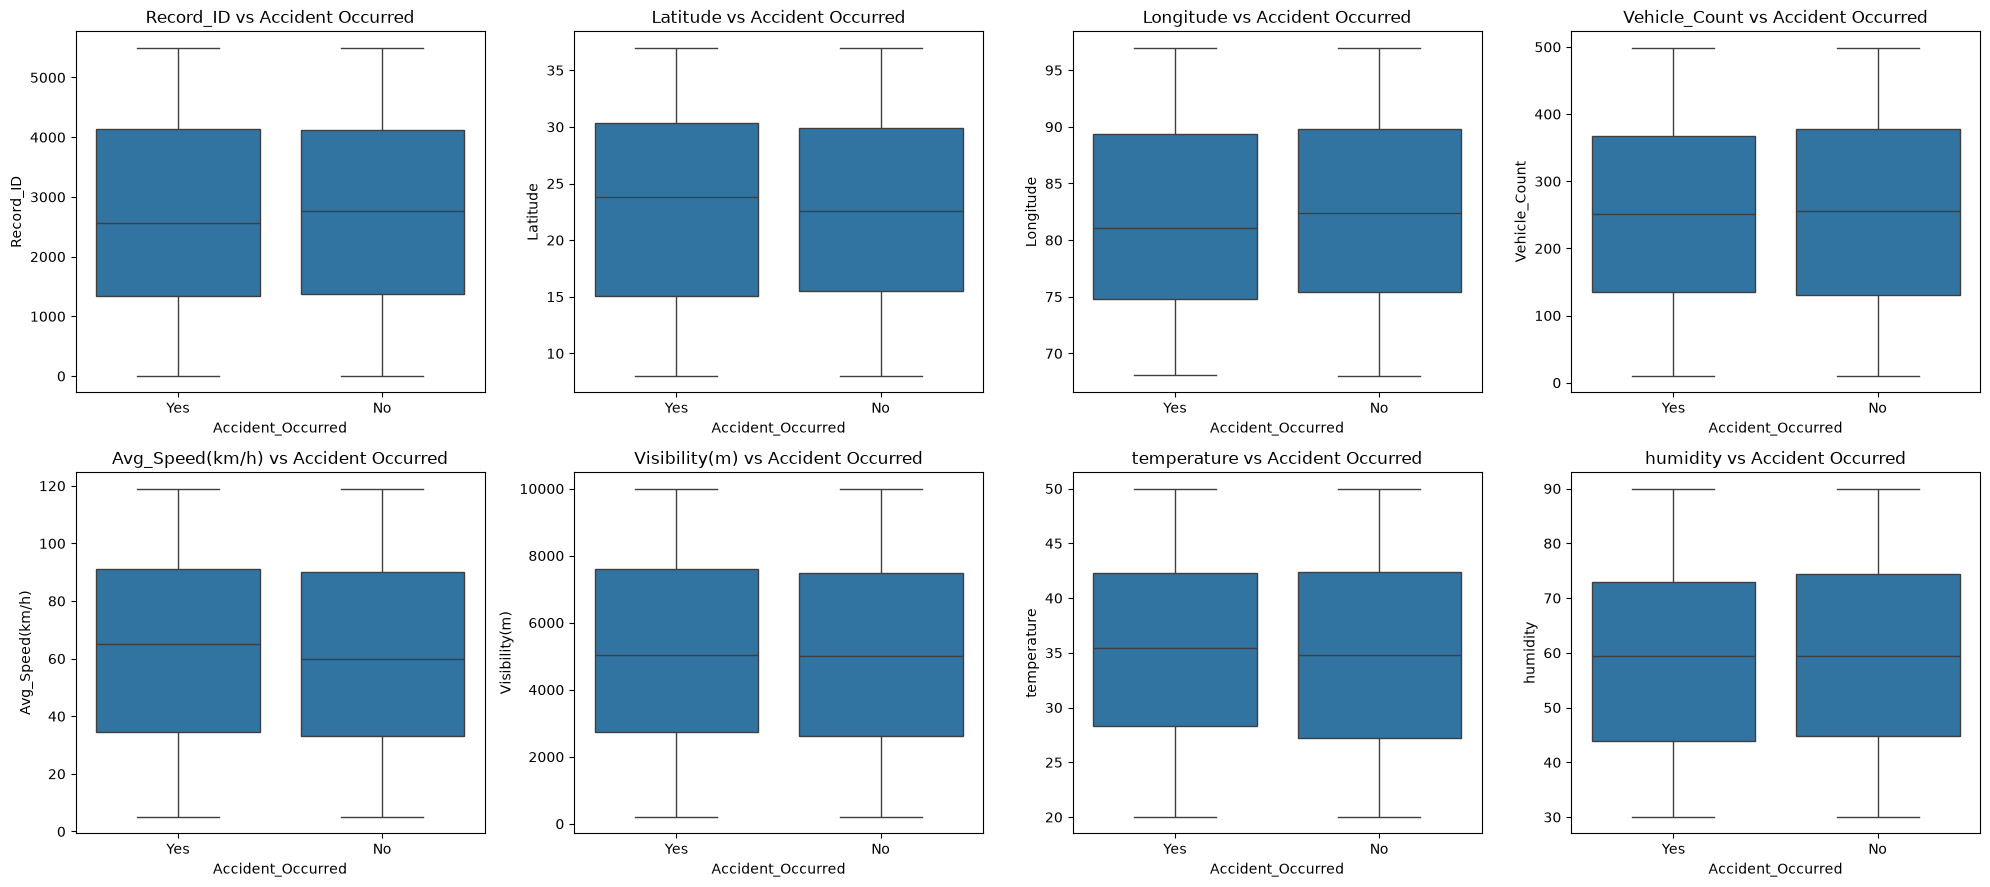

In [23]:
plt.figure(figsize=(20, 35))
for i, col in enumerate(numeric_cols):
    plt.subplot(8, 4, i + 1)
    sns.boxplot(x='Accident_Occurred', y=df[col], data=df)
    plt.title(f'{col} vs Accident Occurred')
plt.tight_layout()
plt.show()

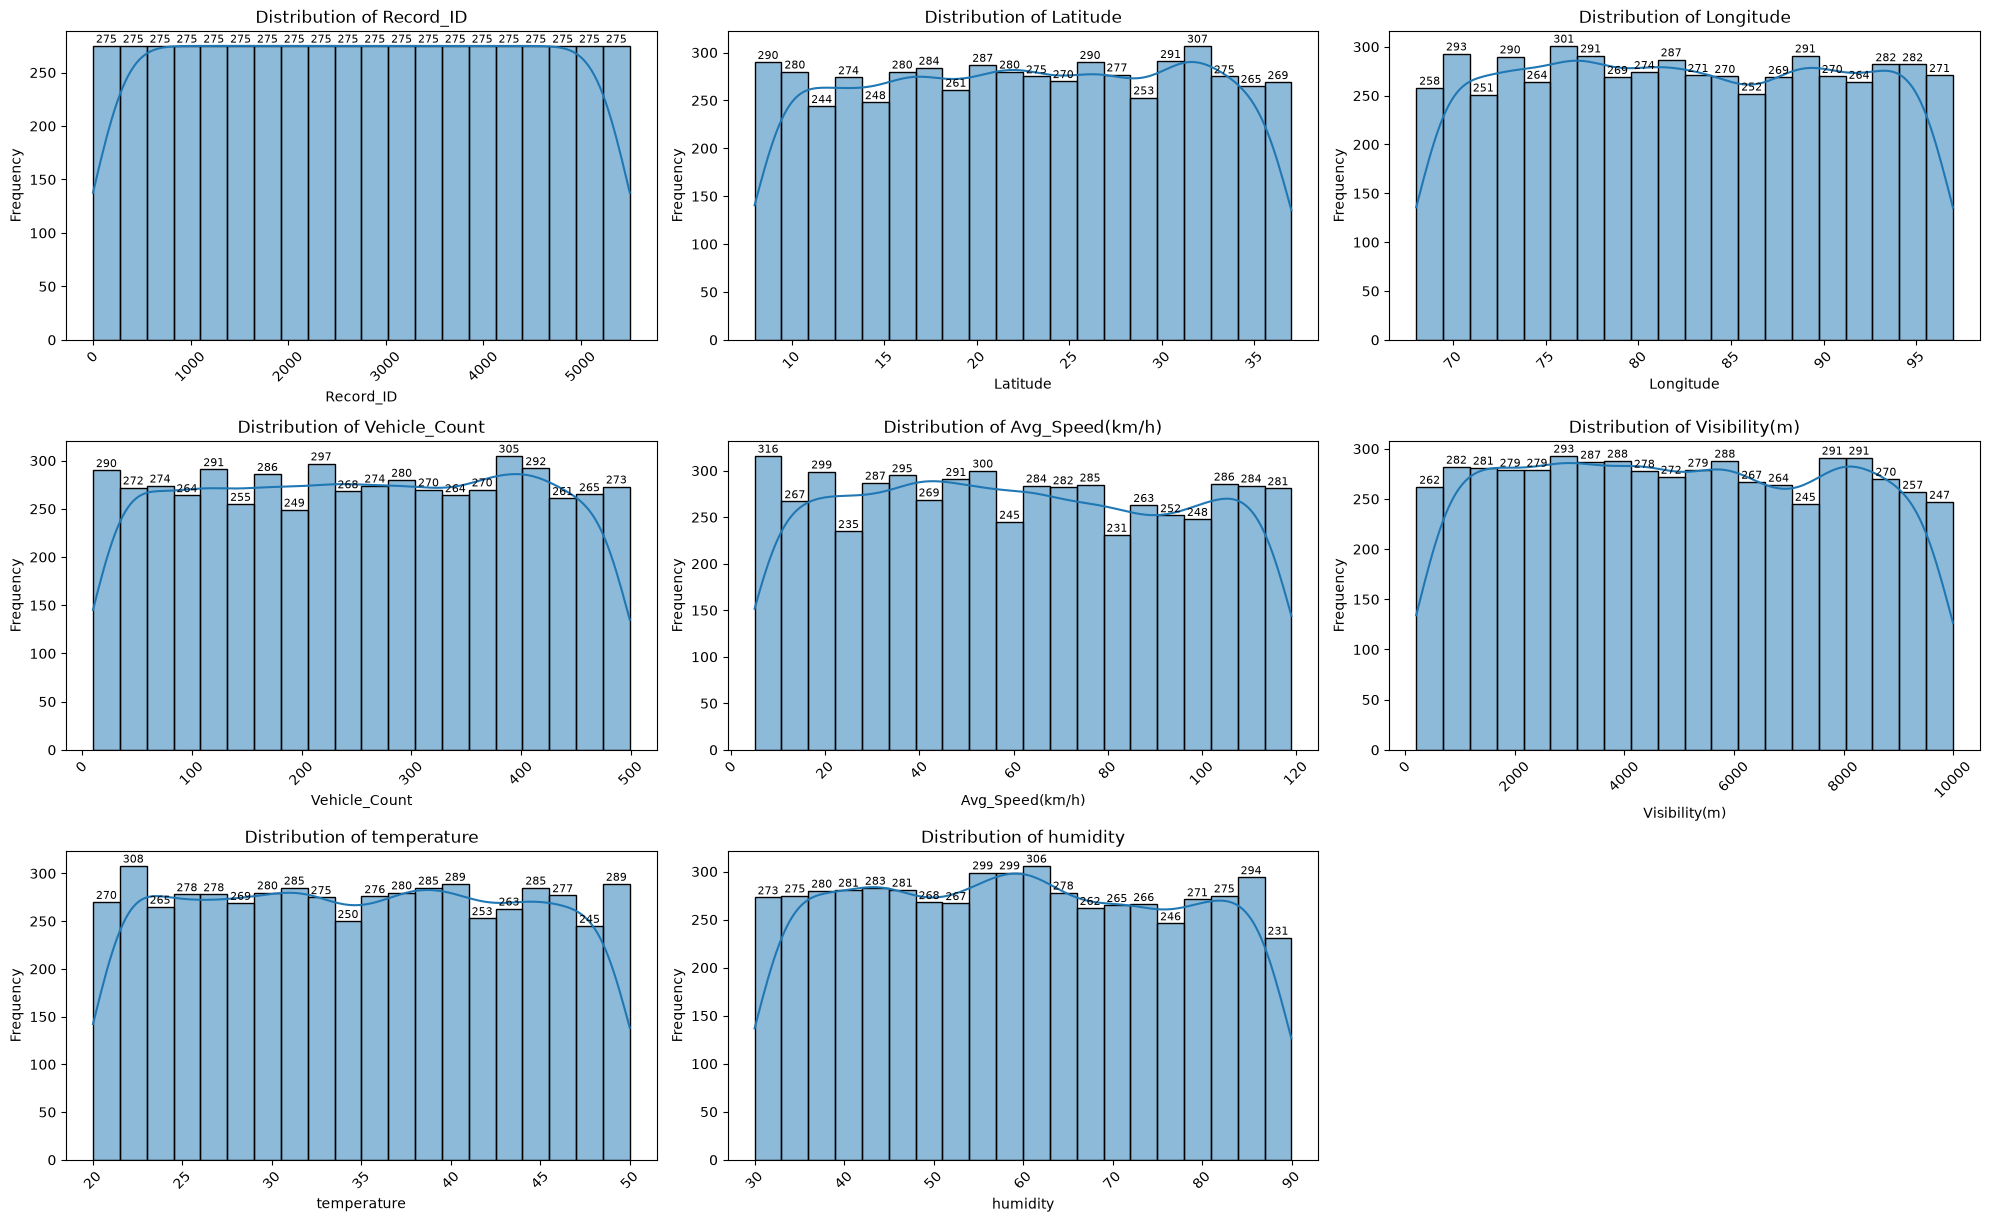

In [24]:
plt.figure(figsize=(20, 20))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(5, 3, i)

    ax = sns.histplot(df[col], kde=True, bins=20)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    # Add count labels on each bar
    for p in ax.patches:
        height = p.get_height()
        ax.text(
            p.get_x() + p.get_width()/2,
            height + 0.5,
            int(height),
            ha='center',
            va='bottom',
            fontsize=8
        )

    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
%pip install altair

In [27]:
import altair as alt

In [28]:
# Show Average Temperature by country
columns_to_average = ['Avg_Speed(km/h)', 'Visibility(m)', 'temperature', 'Latitude', 'Longitude']
weather_averages = df.groupby('Weather')[columns_to_average].mean().reset_index()

chart_weather = alt.Chart(weather_averages).mark_bar().encode(
    x=alt.X('Avg_Speed(km/h):Q', title='Average Speed(km/h)'),
    y=alt.Y('Weather:N', title='Weather', sort ='-x'),
    tooltip=[
        alt.Tooltip('Weather:N', title='weather'),
        alt.Tooltip('Avg_Speed(km/h):Q', title= 'Avg. Weath', format='.1f')
    ]    
).properties(
    title= 'Average Speed(km/h) by Weather'
).interactive()

# chart_temp.save('barchart_avg_weather.json')

chart_weather

alt.Chart(...)

In [29]:
chart_visibility = alt.Chart(weather_averages).mark_bar().encode(
    x=alt.X('Visibility(m):Q', title='Average Visibility'),
    y=alt.Y('Weather:N', title='Weather', sort='-x'),
    tooltip=[
        alt.Tooltip('Weather:N', title='Weather'),
        alt.Tooltip('Visibility(m):Q', title='Avg. Visibility', format=',.0f')

    ]
).properties(
    title='Average Visibility by Country'
).interactive()

# chart_energy.save('barchart_energy_consumption.json')

chart_visibility

alt.Chart(...)

In [30]:
columns_to_average = ['Avg_Speed(km/h)', 'Visibility(m)', 'temperature']
weather_averages = df.groupby('Weather')[columns_to_average].mean().reset_index()

chart_temperature = alt.Chart(weather_averages).mark_bar().encode(
    x=alt.X('temperature:Q', title='Average temperature'),
    y=alt.Y('Weather:N', title='Weather', sort ='-x'),
    tooltip=[
        alt.Tooltip('Weather:N', title='weather'),
        alt.Tooltip('temperature:Q', title= 'Avg. teamper', format='.1f')
    ]    
).properties(
    title= 'Average temperature by Weather'
).interactive()

# chart_temp.save('barchart_avg_weather.json')

chart_temperature

alt.Chart(...)

In [31]:
chart_latitude = alt.Chart(weather_averages).mark_bar().encode(
    x=alt.X('Latitude:Q', title='Average Latitude'),
    y=alt.Y('Weather:N', title='Weather', sort ='-x'),
    tooltip=[
        alt.Tooltip('Weather:N', title='weather'),
        alt.Tooltip('Latitude:Q', title= 'Avg. Latitude', format='.1f')
    ]    
).properties(
    title= 'Average Latitude by Weather'
).interactive()

# chart_temp.save('barchart_avg_weather.json')

chart_latitude

alt.Chart(...)

In [32]:
chart_longitude = alt.Chart(weather_averages).mark_bar().encode(
    x=alt.X('Longitude:Q', title='Average Longitude'),
    y=alt.Y('Weather:N', title='Weather', sort ='-x'),
    tooltip=[
        alt.Tooltip('Weather:N', title='weather'),
        alt.Tooltip('Longitude:Q', title= 'Avg. Longitude', format='.1f')
    ]    
).properties(
    title= 'Average Longitude by Weather'
).interactive()

# chart_temp.save('barchart_avg_weather.json')

chart_longitude

alt.Chart(...)

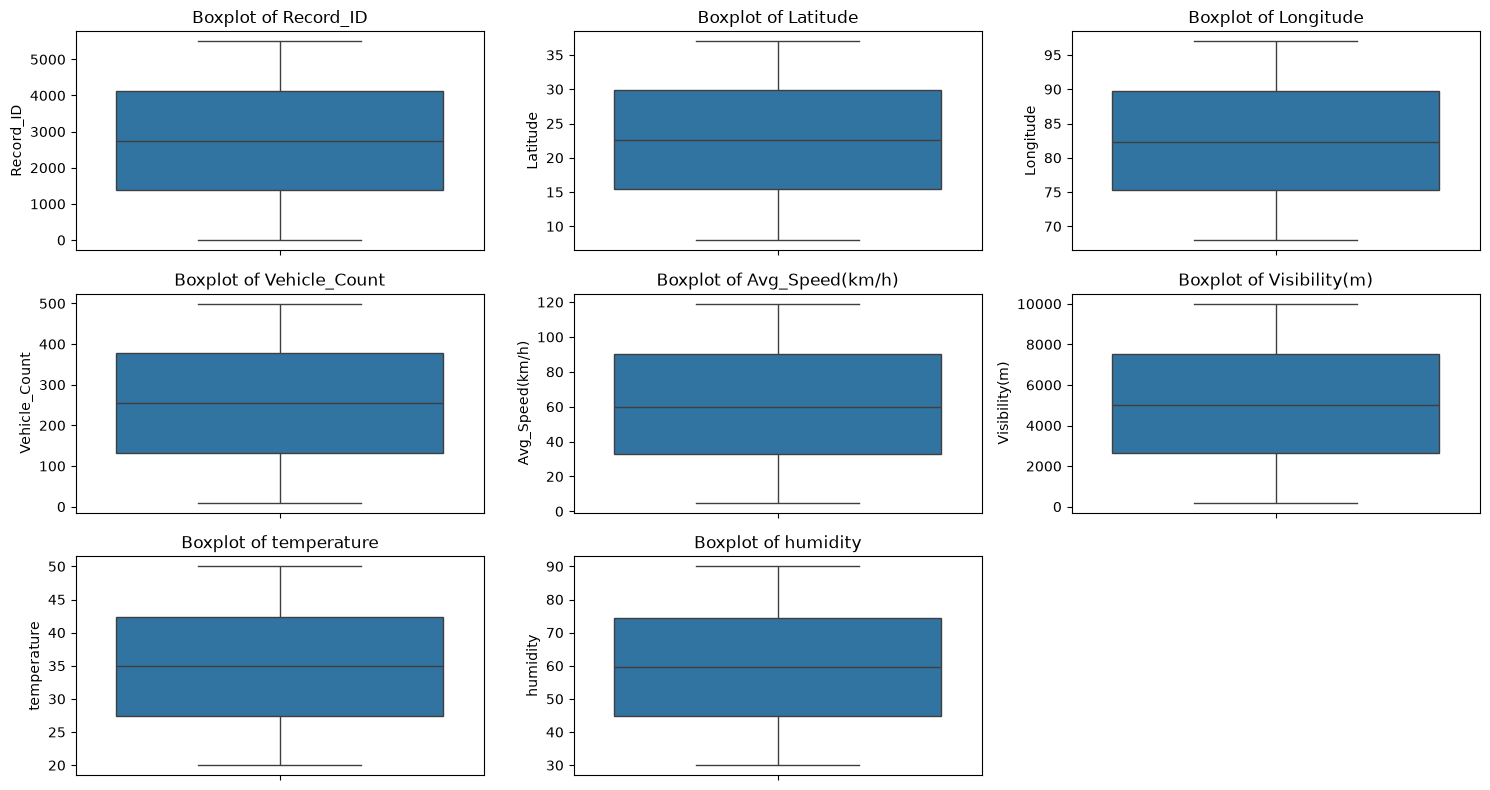

In [33]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=df, y=col)
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [34]:
correlation_matrix = df[numeric_cols].corr()

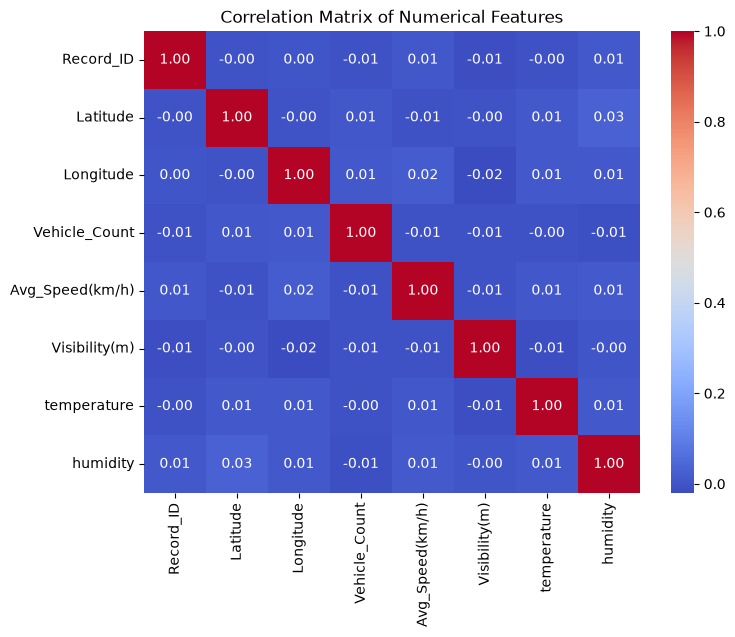

In [35]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [39]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [40]:
df['Accident_Occurred'] = LabelEncoder().fit_transform(df['Accident_Occurred'])

In [41]:
df = pd.get_dummies(df, columns=['Vehicle_Type', 'Traffic_Density', 'Weather', 'Road_Condition',
                                 'Accident_Severity', 'Alert_Generated'], drop_first=True)
df.head()

,Record_ID,Latitude,Longitude,Vehicle_Count,Avg_Speed(km/h),Visibility(m),Accident_Occurred,temperature,humidity,Vehicle_Type_Bus,...,Weather_Rain,Weather_Snow,Weather_Storm,Road_Condition_Slippery,Road_Condition_Under Maintenance,Road_Condition_Wet,Accident_Severity_Fatal,Accident_Severity_Major,Accident_Severity_Minor,Alert_Generated_Yes
0,1,32.004714,76.971961,419,90,5663,1,31.24,61.12,False,...,False,False,False,False,True,False,False,True,False,True
1,2,10.632732,77.828652,232,104,896,0,48.52,33.07,False,...,True,False,False,False,False,True,False,False,False,False
2,3,12.258165,88.810189,339,100,9369,0,41.96,43.97,True,...,False,False,True,False,True,False,False,False,False,False
3,4,34.289950,95.415253,74,63,2510,1,37.96,59.52,False,...,False,False,False,True,False,False,True,False,False,False
4,5,31.698993,77.675486,187,73,3447,0,24.68,48.61,False,...,False,False,True,False,False,True,False,False,False,False


In [42]:
df= df.replace({True: 1, False:0})
df.head()

,Record_ID,Latitude,Longitude,Vehicle_Count,Avg_Speed(km/h),Visibility(m),Accident_Occurred,temperature,humidity,Vehicle_Type_Bus,...,Weather_Rain,Weather_Snow,Weather_Storm,Road_Condition_Slippery,Road_Condition_Under Maintenance,Road_Condition_Wet,Accident_Severity_Fatal,Accident_Severity_Major,Accident_Severity_Minor,Alert_Generated_Yes
0,1,32.004714,76.971961,419,90,5663,1,31.24,61.12,0,...,0,0,0,0,1,0,0,1,0,1
1,2,10.632732,77.828652,232,104,896,0,48.52,33.07,0,...,1,0,0,0,0,1,0,0,0,0
2,3,12.258165,88.810189,339,100,9369,0,41.96,43.97,1,...,0,0,1,0,1,0,0,0,0,0
3,4,34.289950,95.415253,74,63,2510,1,37.96,59.52,0,...,0,0,0,1,0,0,1,0,0,0
4,5,31.698993,77.675486,187,73,3447,0,24.68,48.61,0,...,0,0,1,0,0,1,0,0,0,0


In [43]:
y = df['Accident_Occurred']
X = df.drop(['Accident_Occurred'], axis=1)

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [45]:
scaler = StandardScaler()

In [46]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LogisticRegression()

In [47]:
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [48]:
y_pred = model.predict(X_test_scaled)

In [49]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9854545454545455
Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       997
           1       1.00      0.84      0.92       103

    accuracy                           0.99      1100
   macro avg       0.99      0.92      0.95      1100
weighted avg       0.99      0.99      0.98      1100



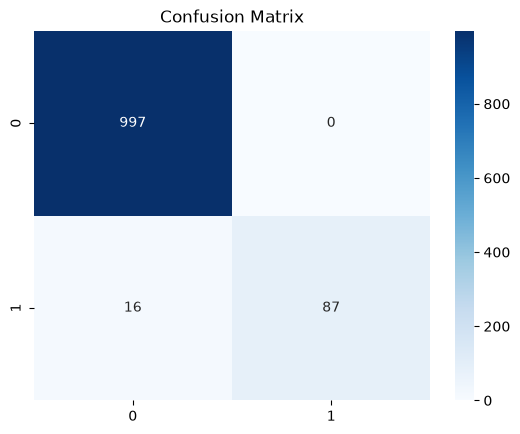

In [50]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap="Blues", fmt="d")
plt.title("Confusion Matrix")
plt.show()

In [51]:
model = RandomForestClassifier()

In [52]:
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [53]:
y_pred = model.predict(X_test)

In [54]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9854545454545455
Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       997
           1       1.00      0.84      0.92       103

    accuracy                           0.99      1100
   macro avg       0.99      0.92      0.95      1100
weighted avg       0.99      0.99      0.98      1100



In [55]:
model = DecisionTreeClassifier()

In [56]:
model.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [57]:
y_pred = model.predict(X_test)

In [58]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9481818181818182
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       997
           1       0.68      0.84      0.75       103

    accuracy                           0.95      1100
   macro avg       0.83      0.90      0.86      1100
weighted avg       0.96      0.95      0.95      1100



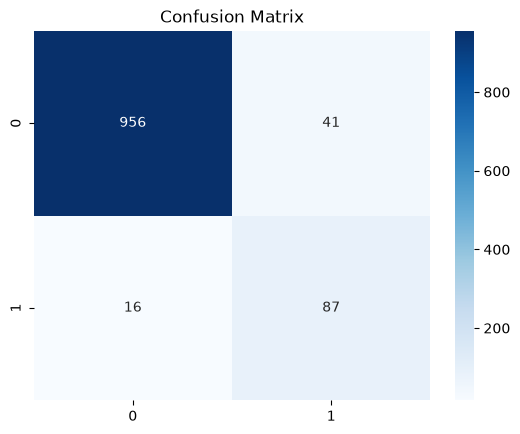

In [59]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap="Blues", fmt="d")
plt.title("Confusion Matrix")
plt.show()